### Problem 1

### Task 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Harrison universal coefficients
hbar2_m = 7.619964  # eV Angstrom^2

eta = np.array([-1.40, 1.84, 3.24, -0.81])

bond_signs = np.array([
    [ 1,  1,  1],
    [ 1, -1, -1],
    [-1,  1, -1],
    [-1, -1,  1]
])

def build_model(a, eps_A, eps_B):

    # Nearest-neighbor bond length and directions
    d = np.sqrt(3) * a / 4
    delta = a / 4 * bond_signs
    directions = delta / d

    # Harrison hopping parameters
    V = eta * hbar2_m / d**2
    Vss, Vsp, Vpp_sigma, Vpp_pi = V

    # On-site Hamiltonians
    hA = np.diag([eps_A[0], eps_A[1],
                  eps_A[1], eps_A[1]])

    hB = np.diag([eps_B[0], eps_B[1],
                  eps_B[1], eps_B[1]])

    # Slater-Koster matrix for each bond
    bond_matrices = []

    for u in directions:

        t = np.zeros((4, 4))

        t[0, 0] = Vss
        t[0, 1:] = Vsp * u
        t[1:, 0] = -Vsp * u

        t[1:, 1:] = (
            Vpp_pi * np.eye(3)
            + (Vpp_sigma - Vpp_pi) * np.outer(u, u)
        )

        bond_matrices.append(t)

    bond_matrices = np.array(bond_matrices)

    # Inter-sublattice block
    def T(k):

        phases = np.exp(1j * (delta @ k))

        return np.einsum(
            'q,qij->ij', phases, bond_matrices
        )

    # Full spinless Hamiltonian
    def H(k):

        Tk = T(k)

        return np.block([
            [hA,           Tk],
            [Tk.conj().T,  hB]
        ])

    return H, T, V


# Silicon parameters
d_Si = 2.35  # Angstrom
a_Si = 4 * d_Si / np.sqrt(3)

eps_Si = (-14.79, -7.59)

H_Si, T_Si, V_Si = build_model(
    a_Si, eps_Si, eps_Si
)

print(f"Lattice constant: {a_Si:.6f} Angstrom")
print("Hamiltonian shape:", H_Si(np.zeros(3)).shape)

Lattice constant: 5.427093 Angstrom
Hamiltonian shape: (8, 8)


In [13]:
np.set_printoptions(precision=6, suppress=True)

# Gamma point
k_Gamma = np.zeros(3)

T_Gamma = T_Si(k_Gamma)
H_Gamma = H_Si(k_Gamma)

print("T(Gamma):")
print(T_Gamma)

print("\nH(Gamma):")
print(H_Gamma)

print("\nMatrix dimensions:")
print("T:", T_Gamma.shape)
print("H:", H_Gamma.shape)

# Check Hermiticity
error = np.max(
    np.abs(H_Gamma - H_Gamma.conj().T)
)

print(f"\nHermiticity error = {error:.3e} eV")

T(Gamma):
[[-7.726899+0.j  0.      +0.j  0.      +0.j  0.      +0.j]
 [ 0.      +0.j  2.980375+0.j  0.      +0.j  0.      +0.j]
 [ 0.      +0.j  0.      +0.j  2.980375+0.j  0.      +0.j]
 [ 0.      +0.j  0.      +0.j  0.      +0.j  2.980375+0.j]]

H(Gamma):
[[-14.79    +0.j   0.      +0.j   0.      +0.j   0.      +0.j
   -7.726899+0.j   0.      +0.j   0.      +0.j   0.      +0.j]
 [  0.      +0.j  -7.59    +0.j   0.      +0.j   0.      +0.j
    0.      +0.j   2.980375+0.j   0.      +0.j   0.      +0.j]
 [  0.      +0.j   0.      +0.j  -7.59    +0.j   0.      +0.j
    0.      +0.j   0.      +0.j   2.980375+0.j   0.      +0.j]
 [  0.      +0.j   0.      +0.j   0.      +0.j  -7.59    +0.j
    0.      +0.j   0.      +0.j   0.      +0.j   2.980375+0.j]
 [ -7.726899-0.j   0.      -0.j   0.      -0.j   0.      -0.j
  -14.79    +0.j   0.      +0.j   0.      +0.j   0.      +0.j]
 [  0.      -0.j   2.980375-0.j   0.      -0.j   0.      -0.j
    0.      +0.j  -7.59    +0.j   0.      +0.j   0.    

### Task 2

In [15]:
def analytic_Si_GX(xi):

    eps_s, eps_p = eps_Si
    Vss, Vsp, Vpp_sigma, Vpp_pi = V_Si

    theta = np.pi * xi / 2

    c = np.cos(theta)
    s = np.sin(theta)

    A = 4 * Vss * c
    B = 4 / np.sqrt(3) * Vsp * s

    C = 4 / 3 * (Vpp_sigma + 2 * Vpp_pi) * c
    D = 4 / 3 * (Vpp_sigma - Vpp_pi) * s

    energies = []

    # Four longitudinal eigenvalues
    for lam in [-1, 1]:

        center = (
            eps_s + eps_p + lam * (A + C)
        ) / 2

        radius = 0.5 * np.sqrt(
            (eps_s - eps_p + lam * (A - C))**2
            + 4 * B**2
        )

        energies.extend([
            center - radius,
            center + radius
        ])

    # Transverse eigenvalues (twofold degenerate)
    radius_T = np.sqrt(C**2 + D**2)

    energies.extend([
        eps_p - radius_T,
        eps_p - radius_T,
        eps_p + radius_T,
        eps_p + radius_T
    ])

    return np.sort(energies)

# Print all eight analytic eigenvalues at selected points
for xi in [0.0, 0.5, 1.0]:

    energies = analytic_Si_GX(xi)

    print(f"\nxi = {xi:.1f}")

    for n, energy in enumerate(energies, start=1):

        print(f"E{n} = {energy:.6f} eV")


xi = 0.0
E1 = -22.516899 eV
E2 = -10.570375 eV
E3 = -10.570375 eV
E4 = -10.570375 eV
E5 = -7.063101 eV
E6 = -4.609625 eV
E7 = -4.609625 eV
E8 = -4.609625 eV

xi = 0.5
E1 = -21.337832 eV
E2 = -13.661908 eV
E3 = -13.264465 eV
E4 = -13.264465 eV
E5 = -5.361793 eV
E6 = -4.398467 eV
E7 = -1.915535 eV
E8 = -1.915535 eV

xi = 1.0
E1 = -18.070193 eV
E2 = -18.070193 eV
E3 = -15.040938 eV
E4 = -15.040938 eV
E5 = -4.309807 eV
E6 = -4.309807 eV
E7 = -0.139062 eV
E8 = -0.139062 eV


### Task 3

In [3]:
hopping_names = [
    "Vss_sigma",
    "Vsp_sigma",
    "Vpp_sigma",
    "Vpp_pi"
]

print("Harrison hopping parameters (eV)")

for name, value in zip(hopping_names, V_Si):
    print(f"{name:12s} = {value:10.6f}")


# 801 equally spaced points along Gamma-X
xi_values = np.linspace(0, 1, 801)

E_analytic = np.array([
    analytic_Si_GX(xi)
    for xi in xi_values
])

E_numeric = np.array([
    np.linalg.eigvalsh(
        H_Si(2 * np.pi / a_Si * np.array([0, xi, 0]))
    )
    for xi in xi_values
])

print("\nBand    Gamma (eV)     X (eV)")

for n in range(8):

    print(
        f"{n+1:4d}"
        f"{E_numeric[0, n]:14.6f}"
        f"{E_numeric[-1, n]:14.6f}"
    )

max_error = np.max(
    np.abs(E_analytic - E_numeric)
)

print(f"\nMaximum discrepancy = {max_error:.3e} eV")

Harrison hopping parameters (eV)
Vss_sigma    =  -1.931725
Vsp_sigma    =   2.538838
Vpp_sigma    =   4.470563
Vpp_pi       =  -1.117641

Band    Gamma (eV)     X (eV)
   1    -22.516899    -18.070193
   2    -10.570375    -18.070193
   3    -10.570375    -15.040938
   4    -10.570375    -15.040938
   5     -7.063101     -4.309807
   6     -4.609625     -4.309807
   7     -4.609625     -0.139062
   8     -4.609625     -0.139062

Maximum discrepancy = 1.954e-14 eV


### Task 4

In [4]:
# High-symmetry points, in units of 2*pi/a
points = {
    "L": np.array([0.5, 0.5, 0.5]),
    "G": np.array([0.0, 0.0, 0.0]),
    "X": np.array([0.0, 1.0, 0.0]),
    "U": np.array([0.25, 1.0, 0.25]),
    "K": np.array([0.75, 0.75, 0.0])
}

segments = [
    ("L", "G"),
    ("G", "X"),
    ("X", "U"),
    ("K", "G")
]

# Store individual segments to avoid a U-K connection
k_segments = []
x_segments = []
E_segments = []

x_start = 0
tick_positions = [0]

for start, end in segments:

    q = np.linspace(points[start], points[end], 801)

    length = np.linalg.norm(
        points[end] - points[start]
    )

    x = np.linspace(x_start, x_start + length, 801)

    E = np.array([
        np.linalg.eigvalsh(
            H_Si(2 * np.pi / a_Si * qi)
        )
        for qi in q
    ])

    k_segments.append(q)
    x_segments.append(x)
    E_segments.append(E)

    x_start += length
    tick_positions.append(x_start)


# Find the path-sampled valence and conduction edges
E_path = np.concatenate(E_segments)
k_path = np.concatenate(k_segments)
x_path = np.concatenate(x_segments)

iv = np.argmax(E_path[:, 3])
ic = np.argmin(E_path[:, 4])

VBM = E_path[iv, 3]
CBM = E_path[ic, 4]
gap_Si = CBM - VBM

print(f"VBM = {VBM:.6f} eV")
print("VBM location:", k_path[iv])

print(f"CBM = {CBM:.6f} eV")
print("CBM location:", k_path[ic])

print(f"Band gap = {gap_Si:.6f} eV")

VBM = -10.570375 eV
VBM location: [0. 0. 0.]
CBM = -7.063101 eV
CBM location: [0. 0. 0.]
Band gap = 3.507274 eV


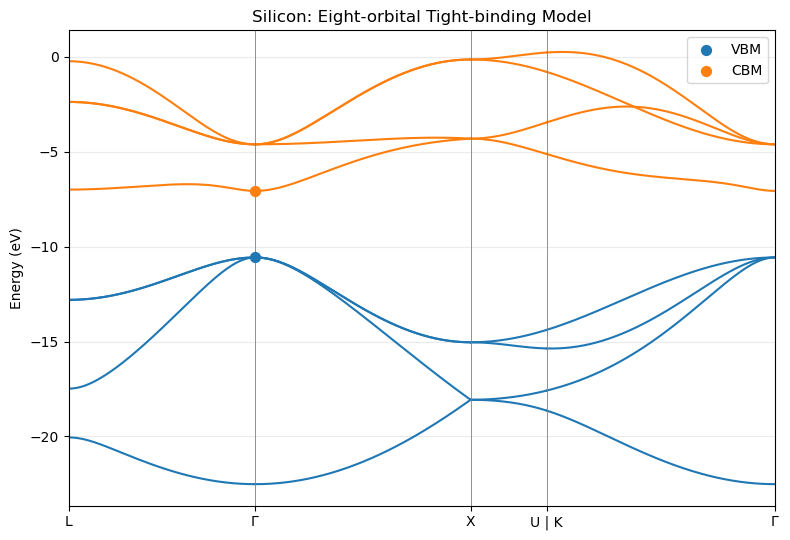

In [5]:
# Plot the eight bands
fig, ax = plt.subplots(figsize=(8, 5.5))

for n in range(8):

    color = "tab:blue" if n < 4 else "tab:orange"

    for x, E in zip(x_segments, E_segments):

        ax.plot(
            x, E[:, n],
            color=color, linewidth=1.5
        )

# Mark the band edges
ax.scatter(x_path[iv], VBM,
           color="tab:blue", s=50, zorder=5,
           label="VBM")

ax.scatter(x_path[ic], CBM,
           color="tab:orange", s=50, zorder=5,
           label="CBM")

for x in tick_positions:
    ax.axvline(x, color="gray", linewidth=0.6)

ax.set_xticks(tick_positions)

ax.set_xticklabels([
    "L", r"$\Gamma$", "X", "U | K", r"$\Gamma$"
])

ax.set_xlim(0, tick_positions[-1])
ax.set_ylabel("Energy (eV)")
ax.set_title("Silicon: Eight-orbital Tight-binding Model")

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig("Si_8_orbital_bands.png", dpi=600)
plt.show()

### Problem 2

### Task 1

In [6]:
# GaAs material parameters
a_GaAs = 5.65  # Angstrom

eps_Ga = (-11.55, -5.67)
eps_As = (-18.92, -8.98)

H_GaAs, T_GaAs, V_GaAs = build_model(
    a_GaAs, eps_Ga, eps_As
)

Vss_GaAs, Vsp_GaAs, Vpp_s_GaAs, Vpp_p_GaAs = V_GaAs

ts = 4 * Vss_GaAs

tp = 4 / 3 * (
    Vpp_s_GaAs + 2 * Vpp_p_GaAs
)

# General analytic two-site eigenvalues
def two_site_levels(eps_A, eps_B, t):

    center = (eps_A + eps_B) / 2

    radius = np.sqrt(
        ((eps_A - eps_B) / 2)**2 + abs(t)**2
    )

    return np.array([
        center - radius,
        center + radius
    ])


Es_GaAs = two_site_levels(eps_Ga[0], eps_As[0], ts)
Ep_GaAs = two_site_levels(eps_Ga[1], eps_As[1], tp)

# Construct the analytic eight-state spectrum
E_GaAs_analytic = list(Es_GaAs)

for energy in Ep_GaAs:
    E_GaAs_analytic.extend([energy] * 3)

E_GaAs_analytic = np.sort(E_GaAs_analytic)

# Direct numerical diagonalization
Gamma = np.zeros(3)

E_GaAs_0 = np.linalg.eigvalsh(H_GaAs(Gamma))

print("Analytic eigenvalues:")
print(E_GaAs_analytic)

print("\nNumerical eigenvalues:")
print(E_GaAs_0)

print(
    "\nMaximum discrepancy:",
    np.max(np.abs(E_GaAs_analytic - E_GaAs_0))
)

Analytic eigenvalues:
[-23.26028387 -10.53446764 -10.53446764 -10.53446764  -7.20971613
  -4.11553236  -4.11553236  -4.11553236]

Numerical eigenvalues:
[-23.26028387 -10.53446764 -10.53446764 -10.53446764  -7.20971613
  -4.11553236  -4.11553236  -4.11553236]

Maximum discrepancy: 3.552713678800501e-15


### Task 2

In [7]:
lambda_Ga = 0.058  # eV
lambda_As = 0.140  # eV

# Dimensionless angular momentum matrices
Lx = np.array([
    [0, 0,  0],
    [0, 0, -1j],
    [0, 1j, 0]
])

Ly = np.array([
    [0,  0, 1j],
    [0,  0, 0],
    [-1j, 0, 0]
])

Lz = np.array([
    [0, -1j, 0],
    [1j,  0, 0],
    [0,   0, 0]
])

# Pauli matrices
sigma_x = np.array([
    [0, 1],
    [1, 0]
])

sigma_y = np.array([
    [0, -1j],
    [1j, 0]
])

sigma_z = np.array([
    [1,  0],
    [0, -1]
])

# Dimensionless 6x6 spin-orbit operator
LS = (
    np.kron(sigma_x, Lx)
    + np.kron(sigma_y, Ly)
    + np.kron(sigma_z, Lz)
)

print("Eigenvalues of L.sigma:")
print(np.linalg.eigvalsh(LS))

print("\nGa isolated p-shell energies:")
print(np.linalg.eigvalsh(lambda_Ga * LS))

print("\nAs isolated p-shell energies:")
print(np.linalg.eigvalsh(lambda_As * LS))

Eigenvalues of L.sigma:
[-2. -2.  1.  1.  1.  1.]

Ga isolated p-shell energies:
[-0.116 -0.116  0.058  0.058  0.058  0.058]

As isolated p-shell energies:
[-0.28 -0.28  0.14  0.14  0.14  0.14]


In [8]:
# p-orbital indices of each site, including both spins
Ga_p_indices = [1, 2, 3, 9, 10, 11]
As_p_indices = [5, 6, 7, 13, 14, 15]

H_SO = np.zeros((16, 16), dtype=complex)

H_SO[np.ix_(Ga_p_indices, Ga_p_indices)] = (
    lambda_Ga * LS
)

H_SO[np.ix_(As_p_indices, As_p_indices)] = (
    lambda_As * LS
)

# Complete spinful Hamiltonian
def H_GaAs_SO(k):

    return np.kron(np.eye(2), H_GaAs(k)) + H_SO


# Numerical spectrum and eigenvectors
E_GaAs_SO, U_GaAs_SO = np.linalg.eigh(
    H_GaAs_SO(Gamma)
)

print("Numerical spin-orbit eigenvalues:")
print(E_GaAs_SO)

Numerical spin-orbit eigenvalues:
[-23.26028387 -23.26028387 -10.77551081 -10.77551081 -10.41451902
 -10.41451902 -10.41451902 -10.41451902  -7.20971613  -7.20971613
  -4.27048919  -4.27048919  -4.03748098  -4.03748098  -4.03748098
  -4.03748098]


In [9]:
# Analytic j = 3/2 eigenvalues
E_j32 = two_site_levels(
    eps_Ga[1] + lambda_Ga,
    eps_As[1] + lambda_As,
    tp
)

# Analytic j = 1/2 eigenvalues
E_j12 = two_site_levels(
    eps_Ga[1] - 2 * lambda_Ga,
    eps_As[1] - 2 * lambda_As,
    tp
)

# Combine all sixteen eigenvalues
E_SO_analytic = (
    list(np.repeat(Es_GaAs, 2))
    + list(np.repeat(E_j32, 4))
    + list(np.repeat(E_j12, 2))
)

E_SO_analytic = np.sort(E_SO_analytic)

print("Analytic SO eigenvalues:")
print(E_SO_analytic)

error_SO = np.max(
    np.abs(E_SO_analytic - E_GaAs_SO)
)

print(f"Maximum discrepancy = {error_SO:.3e} eV")

Analytic SO eigenvalues:
[-23.26028387 -23.26028387 -10.77551081 -10.77551081 -10.41451902
 -10.41451902 -10.41451902 -10.41451902  -7.20971613  -7.20971613
  -4.27048919  -4.27048919  -4.03748098  -4.03748098  -4.03748098
  -4.03748098]
Maximum discrepancy = 1.243e-14 eV


In [16]:

# Full 16x16 Hamiltonian at Gamma
H16_Gamma = H_GaAs_SO(np.zeros(3))

print("Full Hamiltonian shape:", H16_Gamma.shape)

# Numerical eigenvalues of the full Hamiltonian
E16_numeric = np.linalg.eigvalsh(H16_Gamma)


# j = 3/2 two-site block
H_j32 = np.array([
    [eps_Ga[1] + lambda_Ga, tp],
    [tp, eps_As[1] + lambda_As]
])

# j = 1/2 two-site block
H_j12 = np.array([
    [eps_Ga[1] - 2*lambda_Ga, tp],
    [tp, eps_As[1] - 2*lambda_As]
])

print("\nj = 3/2 two-site block:")
print(H_j32)

print("\nj = 1/2 two-site block:")
print(H_j12)


# Analytic eigenvalues from the two-site formula
E_j32 = two_site_levels(
    eps_Ga[1] + lambda_Ga,
    eps_As[1] + lambda_As,
    tp
)

E_j12 = two_site_levels(
    eps_Ga[1] - 2*lambda_Ga,
    eps_As[1] - 2*lambda_As,
    tp
)

print("\nAnalytic j = 3/2 levels:", E_j32)
print("Analytic j = 1/2 levels:", E_j12)


# Combine all 16 states with correct degeneracies
E16_analytic = np.sort(np.concatenate([
    np.repeat(Es_GaAs, 2),
    np.repeat(E_j32, 4),
    np.repeat(E_j12, 2)
]))

print("\nBand   Analytic (eV)   Numerical (eV)")

for n in range(16):
    print(
        f"{n+1:3d}"
        f"{E16_analytic[n]:17.6f}"
        f"{E16_numeric[n]:17.6f}"
    )

max_error = np.max(
    np.abs(E16_analytic - E16_numeric)
)

print(f"\nMaximum discrepancy = {max_error:.3e} eV")


Full Hamiltonian shape: (16, 16)

j = 3/2 two-site block:
[[-5.612     2.749847]
 [ 2.749847 -8.84    ]]

j = 1/2 two-site block:
[[-5.786     2.749847]
 [ 2.749847 -9.26    ]]

Analytic j = 3/2 levels: [-10.414519  -4.037481]
Analytic j = 1/2 levels: [-10.775511  -4.270489]

Band   Analytic (eV)   Numerical (eV)
  1       -23.260284       -23.260284
  2       -23.260284       -23.260284
  3       -10.775511       -10.775511
  4       -10.775511       -10.775511
  5       -10.414519       -10.414519
  6       -10.414519       -10.414519
  7       -10.414519       -10.414519
  8       -10.414519       -10.414519
  9        -7.209716        -7.209716
 10        -7.209716        -7.209716
 11        -4.270489        -4.270489
 12        -4.270489        -4.270489
 13        -4.037481        -4.037481
 14        -4.037481        -4.037481
 15        -4.037481        -4.037481
 16        -4.037481        -4.037481

Maximum discrepancy = 1.332e-14 eV


### Task 3

In [10]:
# Direct Gamma gaps
gap_GaAs_0 = E_GaAs_0[4] - E_GaAs_0[3]

gap_GaAs_SO = E_GaAs_SO[8] - E_GaAs_SO[7]

# Valence-band split-off energy
split_off = E_j32[0] - E_j12[0]

# Ga orbital indices, including both spins
Ga_indices = [0, 1, 2, 3, 8, 9, 10, 11]

# Four degenerate valence-edge eigenstates
valence_quartet = U_GaAs_SO[:, 4:8]

# Total Ga probability in each eigenstate
Ga_weights = np.sum(
    np.abs(valence_quartet[Ga_indices, :])**2,
    axis=0
)

# Average over the four degenerate eigenstates
mean_Ga_weight = np.mean(Ga_weights)

print(f"Gap without SOC = {gap_GaAs_0:.6f} eV")
print(f"Gap with SOC    = {gap_GaAs_SO:.6f} eV")

print(f"Split-off energy = {split_off:.6f} eV")

print("\nGa weight of each valence-edge state:")
print(Ga_weights)

print(f"Mean Ga weight = {mean_Ga_weight:.6f}")
print(f"Mean Ga percentage = {100 * mean_Ga_weight:.4f}%")

print(f"Mean As percentage = {100 * (1 - mean_Ga_weight):.4f}%")

Gap without SOC = 3.324752 eV
Gap with SOC    = 3.204803 eV
Split-off energy = 0.360992 eV

Ga weight of each valence-edge state:
[0.24690444 0.24690444 0.24690444 0.24690444]
Mean Ga weight = 0.246904
Mean Ga percentage = 24.6904%
Mean As percentage = 75.3096%


### Task 4

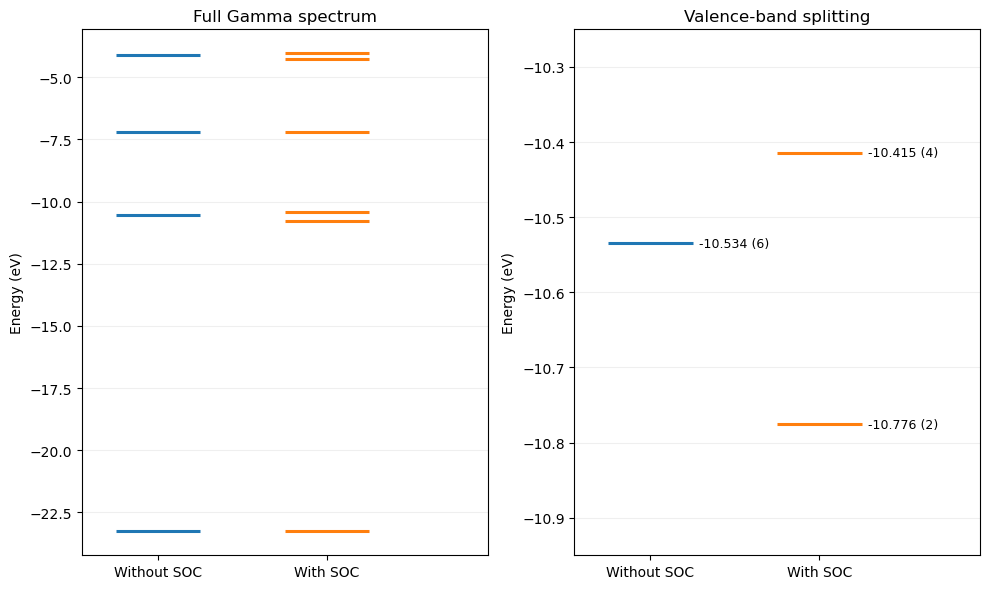

In [11]:
# Group degenerate eigenvalues
def group_levels(energies):

    values, counts = np.unique(
        np.round(energies, 6),
        return_counts=True
    )

    return values, counts


# Include implicit spin degeneracy for fair comparison
levels_0, counts_0 = group_levels(
    np.repeat(E_GaAs_0, 2)
)

levels_SO, counts_SO = group_levels(E_GaAs_SO)

fig, axes = plt.subplots(
    1, 2, figsize=(10, 6),
    gridspec_kw={'width_ratios': [1, 1]}
)


def draw_levels(ax, annotate=False):

    for x, levels, counts, color in [
        (0, levels_0, counts_0, "tab:blue"),
        (1, levels_SO, counts_SO, "tab:orange")
    ]:

        for energy, n in zip(levels, counts):

            ax.hlines(
                energy, x - 0.25, x + 0.25,
                color=color, linewidth=2.2
            )

            if annotate and -10.95 < energy < -10.25:

                ax.text(
                    x + 0.29, energy,
                    f"{energy:.3f} ({n})",
                    va="center", fontsize=9
                )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Without SOC", "With SOC"])
    ax.set_xlim(-0.45, 1.95)
    ax.set_ylabel("Energy (eV)")
    ax.grid(axis="y", alpha=0.2)


# Complete Gamma spectrum
draw_levels(axes[0])
axes[0].set_title("Full Gamma spectrum")

# Zoom into the valence-band levels
draw_levels(axes[1], annotate=True)
axes[1].set_ylim(-10.95, -10.25)
axes[1].set_title("Valence-band splitting")

plt.tight_layout()
plt.savefig("GaAs_Gamma_SO_comparison.png", dpi=600)
plt.show()

In [12]:
rng = np.random.default_rng(537)

# Ten reproducible random k points
random_k = rng.uniform(-1, 1, size=(10, 3))
random_k *= 2 * np.pi / a_GaAs

hermitian_errors = []
TR_errors = []

print("Point   Hermiticity error    k/-k spectrum error")

for i, k in enumerate(random_k):

    Hk = H_GaAs_SO(k)
    Hmk = H_GaAs_SO(-k)

    # Hermiticity
    herm_error = np.max(
        np.abs(Hk - Hk.conj().T)
    )

    # Time-reversal-related eigenvalues
    Ek = np.linalg.eigvalsh(Hk)
    Emk = np.linalg.eigvalsh(Hmk)

    TR_error = np.max(np.abs(Ek - Emk))

    hermitian_errors.append(herm_error)
    TR_errors.append(TR_error)

    print(
        f"{i+1:3d}"
        f"{herm_error:20.3e}"
        f"{TR_error:23.3e}"
    )

print("\nMaximum Hermiticity error:")
print(f"{max(hermitian_errors):.3e} eV")

print("Maximum time-reversal spectrum error:")
print(f"{max(TR_errors):.3e} eV")

Point   Hermiticity error    k/-k spectrum error
  1           0.000e+00              3.553e-14
  2           0.000e+00              2.842e-14
  3           0.000e+00              8.882e-15
  4           0.000e+00              1.243e-14
  5           0.000e+00              1.776e-14
  6           0.000e+00              2.132e-14
  7           0.000e+00              7.105e-15
  8           0.000e+00              2.665e-14
  9           0.000e+00              2.842e-14
 10           0.000e+00              1.776e-14

Maximum Hermiticity error:
0.000e+00 eV
Maximum time-reversal spectrum error:
3.553e-14 eV
